In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

In [2]:
df = pd.read_csv("C:/Users/Administrator/Downloads/marketing-ab-test/marketing_AB.csv")
df.columns = ["row_no", "user_id", "test_group", "converted",
              "total_ads", "most_ads_day", "most_ads_hour"]   # bỏ dấu cách trong tên cột

print(df.shape)                       # (588101, 7)
print(df["converted"].dtype)          # bool
df.head()

(588101, 7)
bool


,row_no,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [3]:
summary = (df.groupby("test_group")["converted"]
             .agg(so_nguoi="count", so_nguoi_mua="sum"))
summary["ty_le_pct"] = 100 * summary["so_nguoi_mua"] / summary["so_nguoi"]
summary

,so_nguoi,so_nguoi_mua,ty_le_pct
test_group,,,
ad,564577,14423,2.554656
psa,23524,420,1.785411


In [4]:
x = np.array([summary.loc["ad", "so_nguoi_mua"], summary.loc["psa", "so_nguoi_mua"]])
n = np.array([summary.loc["ad", "so_nguoi"],     summary.loc["psa", "so_nguoi"]])

z, p_value = proportions_ztest(count=x, nobs=n, alternative="two-sided")
print(f"z = {z:.2f}")
print(f"p-value = {p_value:.2e}")

z = 7.37
p-value = 1.71e-13


In [6]:
p_ad, p_psa = x / n
diff = p_ad - p_psa

lo, hi = confint_proportions_2indep(x[0], n[0], x[1], n[1],
                                   method="wald", compare="diff")
print(f"Chênh lệch: {100*diff:.3f} điểm %")
print(f"Khoảng tin cậy 95%: {100*lo:.3f} đến {100*hi:.3f} điểm %")
print(f"Lift: {100*diff/p_psa:.1f}%")

Chênh lệch: 0.769 điểm %
Khoảng tin cậy 95%: 0.595 đến 0.943 điểm %
Lift: 43.1%


In [7]:
rng = np.random.default_rng(42)          # cố định để chạy lại ra cùng kết quả
B = 10_000

boot_ad  = rng.binomial(n[0], p_ad,  B) / n[0]
boot_psa = rng.binomial(n[1], p_psa, B) / n[1]
boot_diff = boot_ad - boot_psa
boot_lift = boot_diff / boot_psa

print("Bootstrap 95% chênh lệch (điểm %):", np.round(100 * np.percentile(boot_diff, [2.5, 97.5]), 3))
print("Bootstrap 95% lift (%):", np.round(100 * np.percentile(boot_lift, [2.5, 97.5]), 1))

Bootstrap 95% chênh lệch (điểm %): [0.596 0.939]
Bootstrap 95% lift (%): [30.5 57.7]


In [8]:
z_alpha = stats.norm.ppf(1 - 0.05 / 2)   # 1,96
z_beta  = stats.norm.ppf(0.80)           # 0,84
mde = (z_alpha + z_beta) * np.sqrt(p_psa * (1 - p_psa) * (1 / n[0] + 1 / n[1]))

print(f"MDE = {100*mde:.3f} điểm % (tương đương lift {100*mde/p_psa:.1f}%)")
print(f"Hiệu ứng quan sát được gấp {diff/mde:.1f} lần MDE")

MDE = 0.247 điểm % (tương đương lift 13.8%)
Hiệu ứng quan sát được gấp 3.1 lần MDE


Notebook đang chạy tại: c:\Users\Administrator\Downloads\marketing-ab-test\marketing-ab-test\notebooks


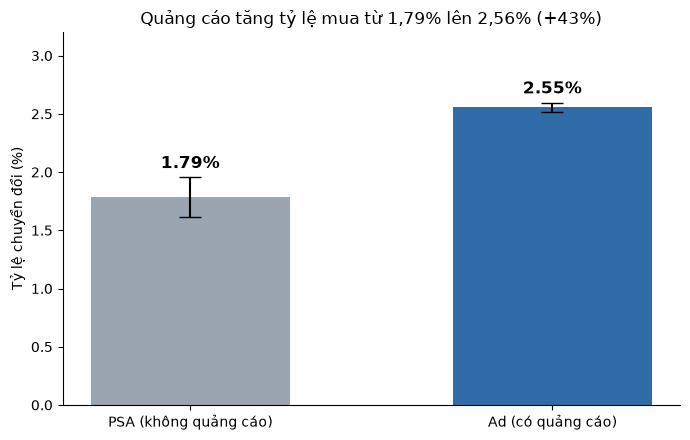

Đã lưu ảnh tại: c:\Users\Administrator\Downloads\marketing-ab-test\marketing-ab-test\images\conversion_by_group.png


In [9]:
import os

# Tạo thư mục images (nằm cạnh thư mục notebooks) nếu chưa có
os.makedirs("../images", exist_ok=True)
print("Notebook đang chạy tại:", os.getcwd())

fig, ax = plt.subplots(figsize=(7, 4.5))
groups = ["PSA (không quảng cáo)", "Ad (có quảng cáo)"]
rates  = [100 * p_psa, 100 * p_ad]
errors = [100 * 1.96 * np.sqrt(p * (1 - p) / m) for p, m in [(p_psa, n[1]), (p_ad, n[0])]]

ax.bar(groups, rates, yerr=errors, capsize=8, color=["#9AA5B1", "#2F6CA8"], width=0.55)
for i, r in enumerate(rates):
    ax.text(i, r + errors[i] + 0.08, f"{r:.2f}%", ha="center", fontsize=12, fontweight="bold")

ax.set_ylabel("Tỷ lệ chuyển đổi (%)")
ax.set_title("Quảng cáo tăng tỷ lệ mua từ 1,79% lên 2,56% (+43%)", fontsize=12)
ax.set_ylim(0, 3.2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../images/conversion_by_group.png", dpi=150)
plt.show()

print("Đã lưu ảnh tại:", os.path.abspath("../images/conversion_by_group.png"))

test_group     ad    psa
ads_bucket              
1–10         0.33   0.40
11–20        0.84   0.82
21–50        2.92   2.18
51–100      11.63   5.77
101–200     17.68  10.64
>200        15.58  15.50


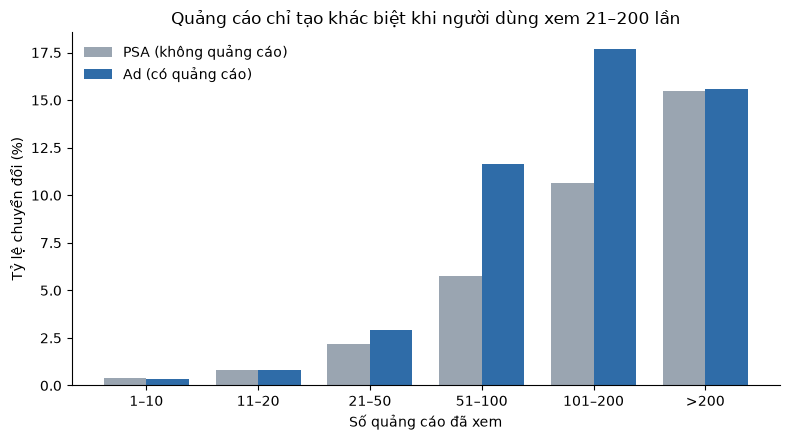

In [10]:
bins   = [0, 10, 20, 50, 100, 200, np.inf]
labels = ["1–10", "11–20", "21–50", "51–100", "101–200", ">200"]
df["ads_bucket"] = pd.cut(df["total_ads"], bins=bins, labels=labels)

by_bucket = (df.groupby(["ads_bucket", "test_group"], observed=True)["converted"]
               .mean().unstack() * 100)
print(by_bucket.round(2))          # phải khớp ket_qua_05.txt, mục 5.3

x = np.arange(len(labels)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - w/2, by_bucket["psa"], w, label="PSA (không quảng cáo)", color="#9AA5B1")
ax.bar(x + w/2, by_bucket["ad"],  w, label="Ad (có quảng cáo)",     color="#2F6CA8")
ax.set_xticks(x, labels)
ax.set_xlabel("Số quảng cáo đã xem")
ax.set_ylabel("Tỷ lệ chuyển đổi (%)")
ax.set_title("Quảng cáo chỉ tạo khác biệt khi người dùng xem 21–200 lần", fontsize=12)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../images/conversion_by_ads_bucket.png", dpi=150)
plt.show()

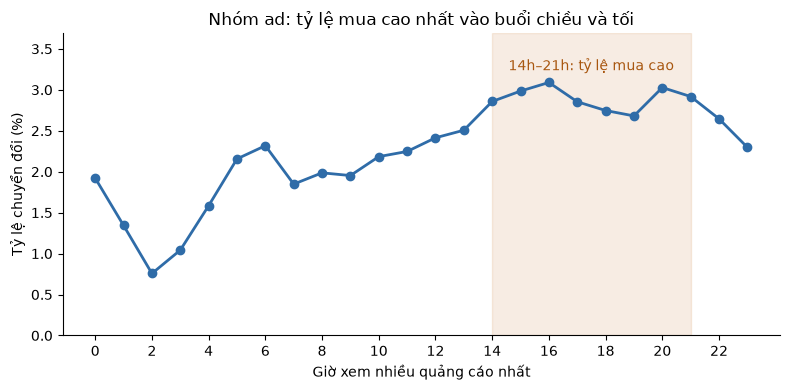

In [11]:
by_hour = df[df["test_group"] == "ad"].groupby("most_ads_hour")["converted"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(by_hour.index, by_hour.values, marker="o", color="#2F6CA8", linewidth=2)
ax.axvspan(14, 21, color="#C46A1A", alpha=0.12)
ax.text(17.5, by_hour.max() + 0.15, "14h–21h: tỷ lệ mua cao", ha="center", color="#A8560F")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Giờ xem nhiều quảng cáo nhất")
ax.set_ylabel("Tỷ lệ chuyển đổi (%)")
ax.set_title("Nhóm ad: tỷ lệ mua cao nhất vào buổi chiều và tối", fontsize=12)
ax.set_ylim(0, by_hour.max() + 0.6)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../images/conversion_by_hour.png", dpi=150)
plt.show()